# Outcome Distributions — Stovepipe (fac=0, amb=0)

1. Waiting time for transport at CCP (T1 & T2)
2. Waiting time for care at R1 (T1 & T2)
3. Total T1 mortality distribution
4. Mortality at CCP vs mortality at R1 (compared boxplots)


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
sub = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
print(f"Policy: Stovepipe (fac=0, amb=0), {len(sub)} runs")


Policy: Stovepipe (fac=0, amb=0), 24576 runs


## 1. Waiting Time for Transport at CCP


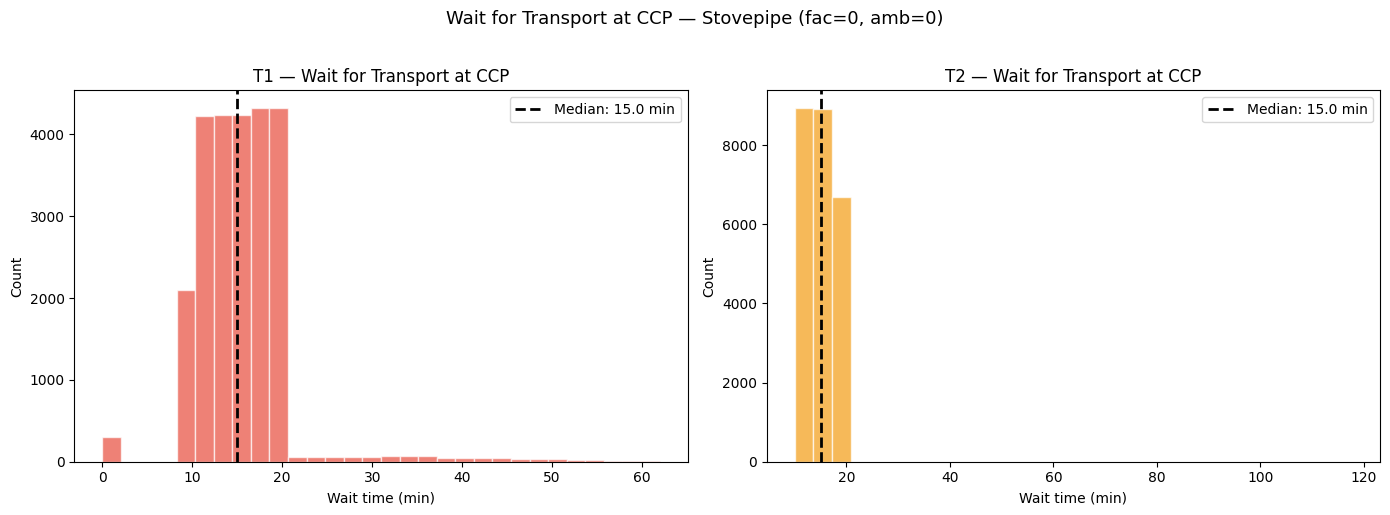

T1: mean=15.6, median=15.0, std=5.4, n=24576
T2: mean=15.1, median=15.0, std=3.9, n=24576


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, triage, color in [(axes[0], "T1", "#e74c3c"), (axes[1], "T2", "#f39c12")]:
    col = f"median_wait_ccp_transport_{triage}"
    vals = sub[col].dropna()
    ax.hist(vals, bins=30, color=color, alpha=0.7, edgecolor="white")
    ax.axvline(vals.median(), color="black", linewidth=2, linestyle="--", label=f"Median: {vals.median():.1f} min")
    ax.set_xlabel("Wait time (min)")
    ax.set_ylabel("Count")
    ax.set_title(f"{triage} — Wait for Transport at CCP")
    ax.legend()

fig.suptitle("Wait for Transport at CCP — Stovepipe (fac=0, amb=0)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

for t in ["T1", "T2"]:
    col = f"median_wait_ccp_transport_{t}"
    vals = sub[col].dropna()
    print(f"{t}: mean={vals.mean():.1f}, median={vals.median():.1f}, std={vals.std():.1f}, n={len(vals)}")


## 2. Waiting Time for Care at R1


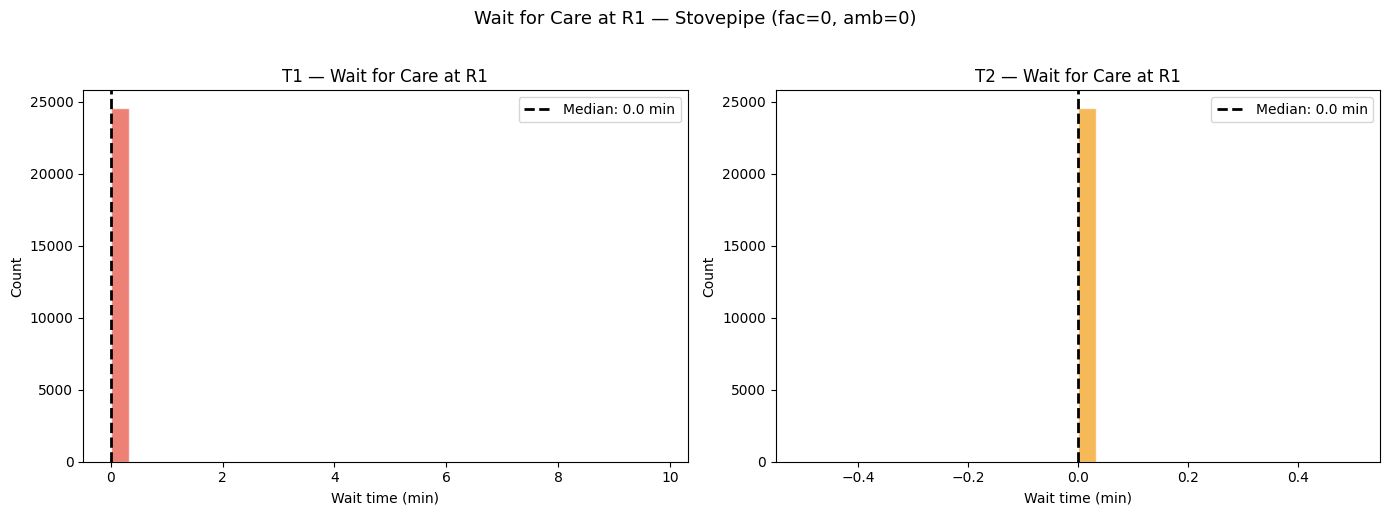

T1: mean=0.0, median=0.0, std=0.1, n=24576
T2: mean=0.0, median=0.0, std=0.0, n=24576


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, triage, color in [(axes[0], "T1", "#e74c3c"), (axes[1], "T2", "#f39c12")]:
    col = f"median_wait_r1_care_{triage}"
    vals = sub[col].dropna()
    ax.hist(vals, bins=30, color=color, alpha=0.7, edgecolor="white")
    ax.axvline(vals.median(), color="black", linewidth=2, linestyle="--", label=f"Median: {vals.median():.1f} min")
    ax.set_xlabel("Wait time (min)")
    ax.set_ylabel("Count")
    ax.set_title(f"{triage} — Wait for Care at R1")
    ax.legend()

fig.suptitle("Wait for Care at R1 — Stovepipe (fac=0, amb=0)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

for t in ["T1", "T2"]:
    col = f"median_wait_r1_care_{t}"
    vals = sub[col].dropna()
    print(f"{t}: mean={vals.mean():.1f}, median={vals.median():.1f}, std={vals.std():.1f}, n={len(vals)}")


## 3. Total T1 Mortality Distribution


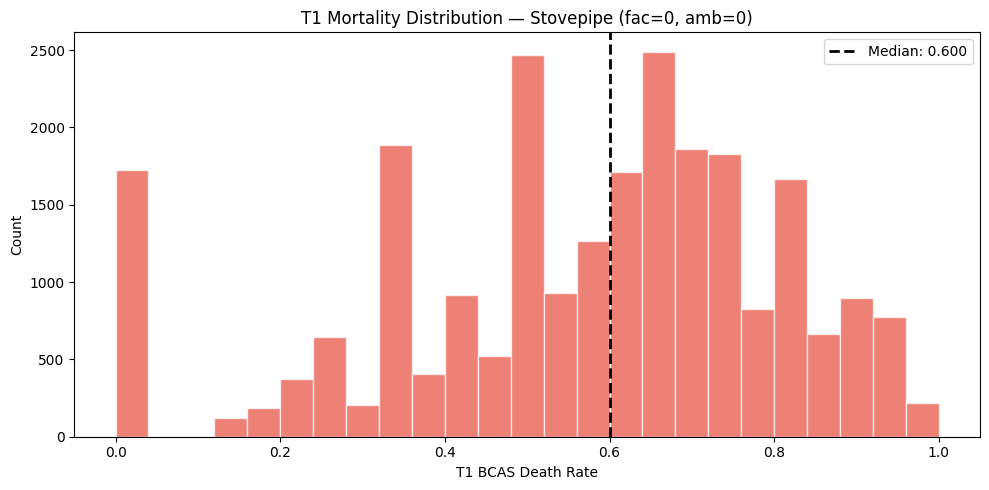

Mean: 0.564, Median: 0.600, Std: 0.242
Nonzero: 22849/24576 (93.0%)


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
vals = sub["death_rate_T1_BCAS"].dropna()
ax.hist(vals, bins=25, color="#e74c3c", alpha=0.7, edgecolor="white")
ax.axvline(vals.median(), color="black", linewidth=2, linestyle="--", label=f"Median: {vals.median():.3f}")
ax.set_xlabel("T1 BCAS Death Rate")
ax.set_ylabel("Count")
ax.set_title("T1 Mortality Distribution — Stovepipe (fac=0, amb=0)")
ax.legend()
plt.tight_layout()
plt.show()

nz = (vals > 0).sum()
print(f"Mean: {vals.mean():.3f}, Median: {vals.median():.3f}, Std: {vals.std():.3f}")
print(f"Nonzero: {nz}/{len(vals)} ({nz/len(vals):.1%})")


## 4. T1 Mortality by Location — CCP Transport vs R1 Care


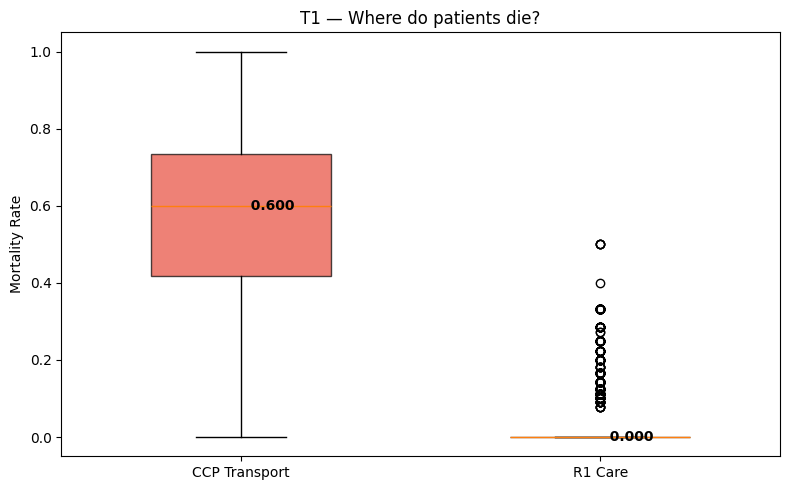

T1 ccp_transport: mean=0.5632, median=0.6000, nonzero=22849/24576 (93.0%)
T1 r1_care: mean=0.0029, median=0.0000, nonzero=379/24576 (1.5%)


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

data = [sub["mortality_ccp_transport_T1"].dropna().values, sub["mortality_r1_care_T1"].dropna().values]
bp = ax.boxplot(data, tick_labels=["CCP Transport", "R1 Care"], patch_artist=True, widths=0.5)
colors = ["#e74c3c", "#3498db"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data):
    med = np.median(d)
    ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Mortality Rate")
ax.set_title("T1 — Where do patients die?")

plt.tight_layout()
plt.show()

for loc in ["ccp_transport", "r1_care"]:
    col = f"mortality_{loc}_T1"
    vals = sub[col].dropna()
    nz = (vals > 0).sum()
    print(f"T1 {loc}: mean={vals.mean():.4f}, median={vals.median():.4f}, nonzero={nz}/{len(vals)} ({nz/len(vals):.1%})")
